In [2]:
import numpy as np
import joblib
import importlib
import matplotlib.pyplot as plt
import os 
import pickle
import bayes_logistic as bl
from collections import defaultdict
import warnings
warnings.filterwarnings("ignore")
from tqdm import trange, tqdm
import math

os.chdir('/Users/eochoa/Documents/Research_Abuj/ASD/Code/')

import pandas as pd
from utils import *
#from linear_utils import *
from logistic_utils import *
from GP_utils import *
from linear_utils import *
import expt_utils as expt_utils
from sklearn.preprocessing import normalize
from sklearn.datasets import load_iris
from sklearn.gaussian_process import GaussianProcessClassifier
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.mixture import GaussianMixture
from sklearn.mixture import BayesianGaussianMixture
from scipy.special import expit, logit
import sklearn
import seaborn as sns
# importlib.reload(expt_utils)
from sklearn.neighbors import NearestNeighbors

from sklearn.metrics import pairwise_distances

from scipy.stats import multivariate_normal

In [3]:
expit = lambda x: 1/(1+np.exp(-x))
def gen_data(N=100):

    #N = 10000
    p = 10
    theta = np.concatenate([np.zeros(1), 5*np.random.rand(p)])#5*np.random.rand(p+1)
    r = np.random.rand(N).reshape(N, 1)-1
    x = np.random.rand(N,p).reshape(N, p)
    x = x - x.mean(0)
    x = r*normalize(x, axis=1, norm='l2')
    #x = np.random.rand(p*N).reshape(N, p)
    x_ = np.concatenate([np.ones((N,1)), x],axis=1)
    f = x_ @ theta
    f = np.power(f,2)
    p = expit(f)
    y = np.random.binomial(1,p)
    #plt.scatter(x[:,0], x[:,1], c=y)
    return x, y, theta

In [4]:
x, y, theta = gen_data()
#y = np.power(y, 3)

In [5]:
y_ = x @ theta[1:]
#theta_ort = np.array([-theta[1:][1],theta[1:][0]])
#theta_ort_span = np.linspace(-1,1,100).reshape((100,1)) * theta_ort + x[y_.argsort()[::-1][(20-1):20],:]
x = x - x.mean(0)
#x = normalize(x, axis=1, norm='l2')

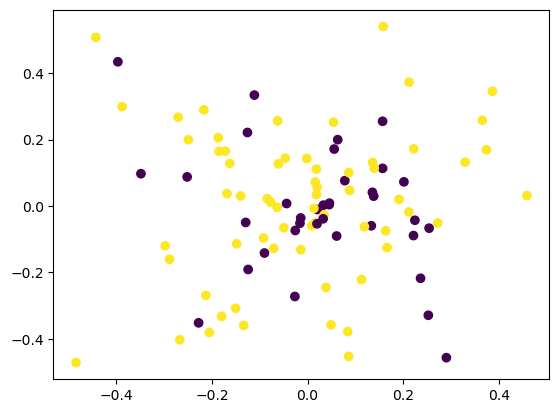

In [6]:
plt.scatter(x[:,0], x[:,1], c=y)

NameError: name 'theta_ort_span' is not defined

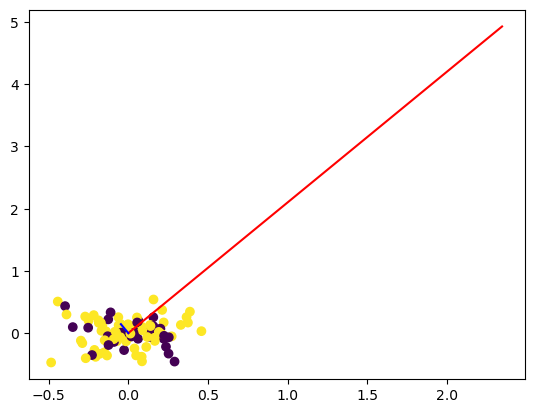

In [7]:
plt.scatter(x[:,0], x[:,1], c=y)

plt.plot(np.concatenate([np.zeros((1,1)), theta[1].reshape(1,1)], axis=0),
np.concatenate([np.zeros((1,1)), theta[2].reshape(1,1)], axis=0),c='r')

plt.plot(np.concatenate([np.zeros((1,1)), x[y.argsort()[::-1][(20-1):20],0].reshape(1,1)], axis=0),
np.concatenate([np.zeros((1,1)), x[y.argsort()[::-1][(20-1):20],1].reshape(1,1)], axis=0),c='b')

#plt.plot(np.concatenate([np.zeros((1,1)), x[y.argsort()[::-1][(20-2):(20-1)],0].reshape(1,1)], axis=0),
#np.concatenate([np.zeros((1,1)), x[y.argsort()[::-1][(20-2):(20-1)],1].reshape(1,1)], axis=0),c='b')

plt.plot(theta_ort_span[:,0],theta_ort_span[:,1])

NameError: name 'theta_ort_span' is not defined

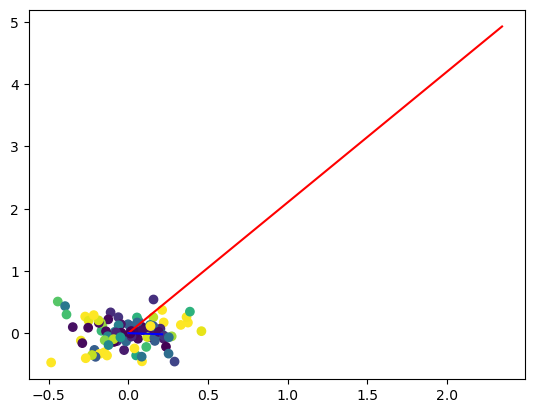

In [8]:
plt.scatter(x[:,0], x[:,1], c=expit(np.power(x @ theta[1:], 2)))
#plt.scatter(theta[1], theta[2],c='r')
#plt.plot(np.zeros((1,2)), theta[1:].reshape(1,2), c='r')
plt.plot(np.concatenate([np.zeros((1,1)), theta[1].reshape(1,1)], axis=0),
np.concatenate([np.zeros((1,1)), theta[2].reshape(1,1)], axis=0),c='r')

plt.plot(np.concatenate([np.zeros((1,1)), x[y_.argsort()[::-1][(20-1):20],0].reshape(1,1)], axis=0),
np.concatenate([np.zeros((1,1)), x[y_.argsort()[::-1][(20-1):20],1].reshape(1,1)], axis=0),c='b')

#plt.plot(np.concatenate([np.zeros((1,1)), x[y.argsort()[::-1][(20-2):(20-1)],0].reshape(1,1)], axis=0),
#np.concatenate([np.zeros((1,1)), x[y.argsort()[::-1][(20-2):(20-1)],1].reshape(1,1)], axis=0),c='b')

plt.plot(theta_ort_span[:,0],theta_ort_span[:,1])

In [198]:
algos_dict = {
  #'Random': [GP_solver, {}, 10, 'Random', 'y'],
  #'Oracle_logistic': [Oracle_logistic, {}, 10, 'Oracle_logistic', 'black'],
  'TS_logistic': [TS_logistic, {}, 10, 'TS_logistic', 'darkblue'],
  'G_logistic': [G_logistic, {}, 10, 'G_logistic', 'blue'],
   'G_logistic_2': [G_logistic, {'k':2}, 10, 'G_logistic_2', 'm']
  #'IDS_logistic': [IDS_logistic, {}, 10, 'IDS_logistic', 'red'],
  #'G_GP': [TS_GP_Rand, {}, 10, 'G_GP', 'green']
    #'TS_GP_True': [TS_GP_True, {}, 10, 'TS_GP_True', 'darkgreen']

}

In [201]:
res_sim = defaultdict(list)
for i in trange(5):
    x, y, _ = gen_data(200)
    n_row, n_col = y.shape[0], 1
    _, n_desc =  x.shape
    cutoff = n_desc
    #T = n_row
    T = 10
    prob_dict = {
        "m": n_row,
        "noise": 0.01,
        "d": cutoff
      }
    prob = logistic_discover(**prob_dict)
    x = x - x.mean(0)
    x = normalize(x, axis=0, norm='l2')
    prob.x = x.copy()
    prob.y = y.copy()

    reg_list = {algo:[] for algo in algos_dict}
    #tau_list = {algo:[] for algo in algos_dict}

    for trial_idx in range(5):
        t_prob = deepcopy(prob)
            # print(prob.x)
        for algo, algo_setup in algos_dict.items():
            algo_func, algo_params, algo_N_trials, _, _ = algo_setup
                        # print(algo_func)
            if not trial_idx < algo_N_trials:
                continue
            solver = algo_func(t_prob, **algo_params)
            reg, _ = solver.run(T)[:2]
                #act_list[algo].append(getattr(solver, "logistic_discover"))
                #act_list[algo].append(t_prob.actions)
                # print(prob.rewards)
            reg_list[algo].append(reg)
                #tau_list[algo].append(tau)

        #for algo in algos_dict:
        #algo_label = algos_dict[algo][3]
        #algo_style = algos_dict[algo][4]
    #y_1 = np.mean(reg_list['Random'], axis = 0)[:T]
    y_2 = np.mean(reg_list['TS_logistic'], axis = 0)[:T]
    y_3 = np.mean(reg_list['G_logistic'], axis = 0)[:T]
    y_4 = np.mean(reg_list['G_logistic_2'], axis = 0)[:T]
    #y_5 = np.mean(reg_list['IDS_logistic'], axis = 0)[:T]
    #y_6 = np.mean(reg_list['G_GP'], axis = 0)[:T]
    #y_7 = np.mean(reg_list['TS_GP_True'], axis = 0)[:T]
    #y_ = y_3 - y_1
    #y_ = y_2 - y_1
            #ci = np.std(reg_list[algo], axis = 0)[:T]
    #plt.plot(range(T), y_, c='b', alpha=.1)
    #res_sim['Random'].append(y_1.max())
    res_sim['TS_logistic'].append(y_2.max())
    res_sim['G_logistic'].append(y_3.max())
    res_sim['G_logistic_2'].append(y_4.max())
    #res_sim['IDS_logistic'].append(y_5.max())
    #res_sim['G_GP'].append(y_6.max())
    #res_sim['TS_GP_True'].append(y_7.max())
    #plt.plot(range(T), y_1, c='r', alpha=.1)
    #plt.plot(range(T),y_2, c='b', alpha=.1)
        #                  algo_style, label=algo_label, alpha=.1)
            #plt.fill_between(range(T), (y_-ci), (y_+ci), color = algo_style, alpha=.1)

            #plt.legend()

100%|█████████████████████████████████████████████| 5/5 [02:19<00:00, 27.89s/it]


<AxesSubplot: >

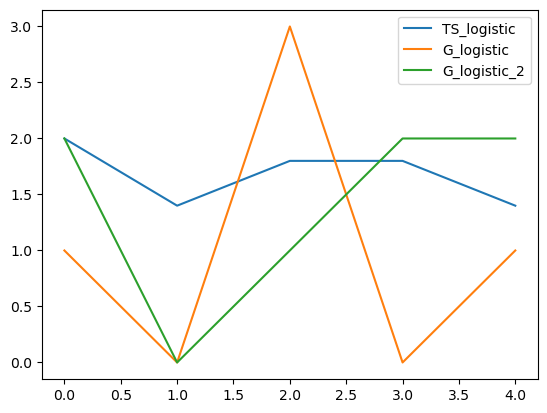

In [202]:
pd.DataFrame(res_sim).plot()

In [203]:
reg_list = {algo:[] for algo in algos_dict}
solver_list = {algo:[] for algo in algos_dict}
    #tau_list = {algo:[] for algo in algos_dict}

for trial_idx in trange(1):
    t_prob = deepcopy(prob)
            # print(prob.x)
    for algo, algo_setup in algos_dict.items():
        algo_func, algo_params, algo_N_trials, _, _ = algo_setup
                        # print(algo_func)
        if not trial_idx < algo_N_trials:
            continue
        if algo == 'G_logistic_2':
            solver = algo_func(t_prob, k=2)
        else:
            solver = algo_func(t_prob, **algo_params)
        reg, _ = solver.run(T)[:2]
                #act_list[algo].append(getattr(solver, "logistic_discover"))
                #act_list[algo].append(t_prob.actions)
                # print(prob.rewards)
        reg_list[algo].append(reg)
        solver_list[algo].append(deepcopy(solver))
                #tau_list[algo].append(tau)

        #for algo in algos_dict:
        #algo_label = algos_dict[algo][3]
        #algo_style = algos_dict[algo][4]

100%|█████████████████████████████████████████████| 1/1 [00:04<00:00,  4.38s/it]


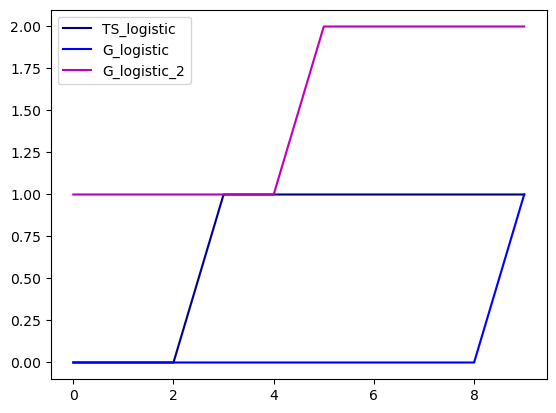

In [204]:
for algo in algos_dict:
    algo_label = algos_dict[algo][3]
    algo_style = algos_dict[algo][4]
    y_ = np.mean(reg_list[algo], axis = 0)[:T]
    ci = np.std(reg_list[algo], axis = 0)[:T]
    plt.plot(range(T), y_,
                  algo_style, label=algo_label)
    plt.fill_between(range(T), (y_-ci), (y_+ci), color = algo_style, alpha=.1)
    
    plt.legend()
    
#reg_mean = np.arange(1,100)*y.sum()/y.shape[0]
#c = np.arange(1,100)*y.sum()/y.shape[0] * (y.shape[0]-y.sum())/y.shape[0] * (y.shape[0]-np.arange(1,100))/(y.shape[0]-1)
#plt.plot(reg_mean,c='r')

#plt.fill_between(range(T), (reg_mean-c), (reg_mean+c), color = 'r', alpha=.1)
#plt.fill_between(range(T), (reg_mean-c), (reg_mean+c), color = 'r', alpha=.1)

In [167]:
np.array(solver_list['G_logistic'][0].prob.actions)

array([ 0, 31, 38, 52, 10, 86, 18, 55, 27, 74, 24, 70, 39, 35,  9, 81, 93,
       32, 61, 53, 16,  8, 30, 57, 42, 50, 25, 59,  1, 79, 36, 80, 22,  2,
       97, 94, 65, 62, 60, 28, 82, 29, 54, 90, 77,  6, 88, 43, 75, 19, 12,
       92, 68, 49, 73, 23, 40, 56, 63,  5, 37, 72, 46, 87, 44, 41, 84, 48,
       69, 17, 64, 11, 21, 47, 14, 78, 67,  4, 58, 13, 76, 96, 51, 89, 99,
       20, 66, 98, 91, 71, 34, 45, 85, 26,  3, 95, 33, 83, 15])

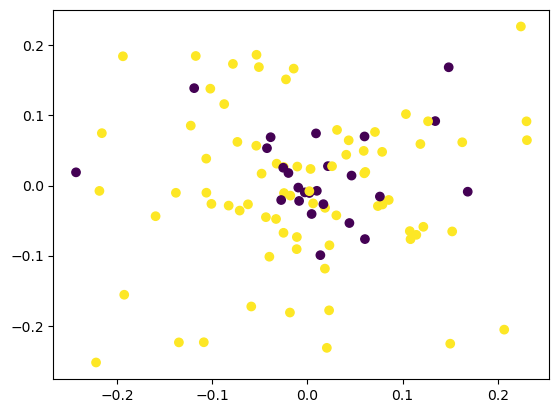

In [170]:
plt.scatter(x[:, 0], x[:, 1], c=y)

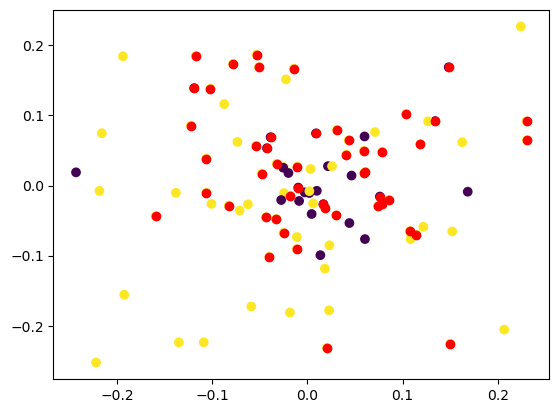

In [174]:
x = solver_list['G_logistic_2'][0].prob.x
y = solver_list['G_logistic_2'][0].prob.y
plt.scatter(x[:, 0], x[:, 1], c=y)
n = 50
plt.scatter(x[solver_list['G_logistic'][0].prob.actions[:n], 0], 
            x[solver_list['G_logistic'][0].prob.actions[:n], 1], 
            c='r')

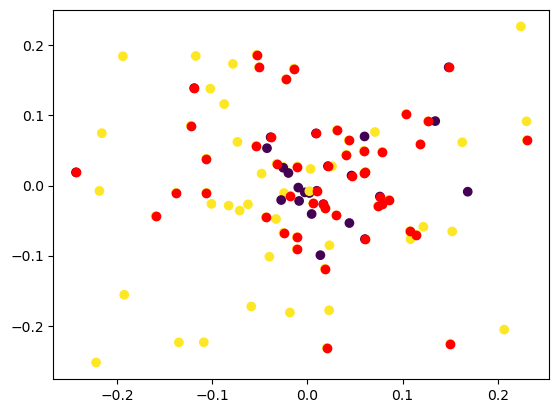

In [176]:
x = solver_list['G_logistic_2'][0].prob.x
y = solver_list['G_logistic_2'][0].prob.y
plt.scatter(x[:, 0], x[:, 1], c=y)
n = 50
plt.scatter(x[solver_list['G_logistic_2'][0].prob.actions[:n], 0], 
            x[solver_list['G_logistic_2'][0].prob.actions[:n], 1], 
            c='r')

In [181]:
n = 100


array([ 1,  2,  3,  4,  5,  6,  6,  7,  7,  8,  9, 10, 11, 11, 12, 13, 14,
       15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 24, 24, 25, 26, 27, 28, 29,
       29, 30, 30, 30, 31, 31, 32, 33, 34, 35, 35, 36, 37, 38, 39, 39, 40,
       40, 41, 41, 42, 43, 43, 44, 45, 46, 47, 47, 47, 47, 48, 48, 49, 49,
       49, 50, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 59, 60, 61, 62, 63,
       64, 65, 66, 66, 66, 67, 68, 69, 70, 71, 72, 73, 74, 74])

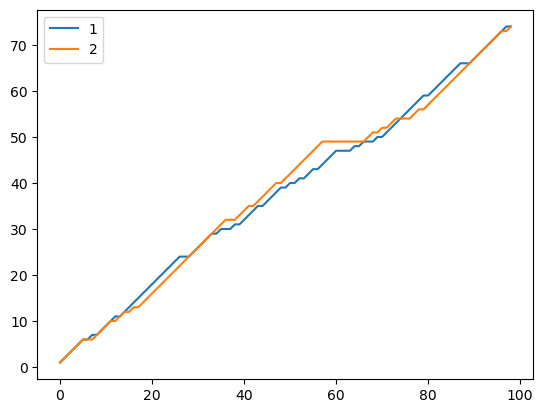

In [185]:
plt.plot(y[solver_list['G_logistic_2'][0].prob.actions[:n]].cumsum(), label='1')
plt.plot(y[solver_list['G_logistic'][0].prob.actions[:n]].cumsum(), label='2')
plt.legend()